# FoggyVision — DataLoader Testing Notebook

This notebook demonstrates loading images and visibility-distance labels from
the project's SQLite database into a PyTorch `DataLoader`, ready for model
training.

**Labels:** `visibilityDistance` from the `image` table.

Supporting code lives in `src/fogvis/dataset.py`.

In [33]:
import sys
from pathlib import Path
import os
from foggy_vision_loader.db import Database
from foggy_vision_loader.db.entities import ImageEntity

import sqlite3
import math

import torch
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image
from torchvision import transforms as tvf
from collections import Counter

from fogvis.dataset import FoggyVisionDataset, get_dataloader
DB_DIR : Path = Path(os.path.abspath(os.path.join(os.getcwd(), os.pardir, "media", "db")))
DB_PATH : Path = Path(os.path.join(DB_DIR, "database.sqlite3"))
IMAGE_DIR : Path = Path(os.path.join(DB_DIR, "images"))

## 1. Inspect the SQLite Database

Quick look at the database structure and how many images are available.

In [34]:
db = Database(DB_PATH)
print(DB_PATH)

with db as conn:
    cur = conn.cursor()
    cur.execute("SELECT id, filePath, visibilityDistance FROM image ORDER BY id")
    rows = cur.fetchall()

print(f"Rows in database: {len(rows)}")
for row in rows:
    vis = row[2]
    print(f"  id={row[0]:3}  path={row[1]}  visibilityDistance={vis:.2f}")

e:\Repos\FoggyVision\media\db\database.sqlite3
Rows in database: 35100
  id=  1  path=2026-05-13_10-00-13_Frame-0.png  visibilityDistance=100.00
  id=  2  path=2026-05-13_10-00-13_Frame-1.png  visibilityDistance=1449.95
  id=  3  path=2026-05-13_10-00-13_Frame-10.png  visibilityDistance=13599.47
  id=  4  path=2026-05-13_10-00-13_Frame-100.png  visibilityDistance=100.00
  id=  5  path=2026-05-13_10-00-13_Frame-1000.png  visibilityDistance=100.00
  id=  6  path=2026-05-13_10-00-13_Frame-1001.png  visibilityDistance=1449.95
  id=  7  path=2026-05-13_10-00-13_Frame-1002.png  visibilityDistance=2799.89
  id=  8  path=2026-05-13_10-00-13_Frame-1003.png  visibilityDistance=4149.84
  id=  9  path=2026-05-13_10-00-13_Frame-1004.png  visibilityDistance=5499.79
  id= 10  path=2026-05-13_10-00-13_Frame-1005.png  visibilityDistance=6849.74
  id= 11  path=2026-05-13_10-00-13_Frame-1006.png  visibilityDistance=8199.68
  id= 12  path=2026-05-13_10-00-13_Frame-1007.png  visibilityDistance=9549.63
  id

## 2. Load Data with `FoggyVisionDataset`

Create a `FoggyVisionDataset` instance.  Every `__getitem__` returns a tuple:

```
(image_tensor: torch.Tensor[3, H, W], label: float)
```

The **label** is the visibility distance.  A `log10` transform is provided so
that labels live on a more manageable numeric scale.

In [35]:
def log_transform(v: float) -> float:
    """Log10-scale the raw visibility distance."""
    return math.log10(v)

def raw_label(v : float) -> float:
    return v

def get_vis_distance_to_miles_transform(v : float) -> torch.Tensor: 
    meters_to_miles : float = 1609.344
    miles : int = int(math.floor(v / meters_to_miles))
    return torch.tensor(int(miles), dtype=torch.long)

def get_tensor_transform(): 
    return tvf.Compose([
        tvf.ToTensor()
    ])
    

In [36]:
# ---------- Basic dataset (no transforms) -----------
dataset = FoggyVisionDataset(
    db_path=DB_PATH,
    image_root=IMAGE_DIR,
    label_transform=get_vis_distance_to_miles_transform,
    transform=get_tensor_transform()
)

print(f"Dataset length: {len(dataset)}")
print(f"File paths   : {dataset.file_paths}")
print(f"Raw visibilities: {dataset.raw_visibilities}")
print(f"Log10 labels  : {dataset.labels.tolist()}")

Dataset length: 35100
File paths   : ['2026-05-13_10-00-13_Frame-0.png', '2026-05-13_10-00-13_Frame-1.png', '2026-05-13_10-00-13_Frame-10.png', '2026-05-13_10-00-13_Frame-100.png', '2026-05-13_10-00-13_Frame-1000.png', '2026-05-13_10-00-13_Frame-1001.png', '2026-05-13_10-00-13_Frame-1002.png', '2026-05-13_10-00-13_Frame-1003.png', '2026-05-13_10-00-13_Frame-1004.png', '2026-05-13_10-00-13_Frame-1005.png', '2026-05-13_10-00-13_Frame-1006.png', '2026-05-13_10-00-13_Frame-1007.png', '2026-05-13_10-00-13_Frame-1008.png', '2026-05-13_10-00-13_Frame-1009.png', '2026-05-13_10-00-13_Frame-101.png', '2026-05-13_10-00-13_Frame-1010.png', '2026-05-13_10-00-13_Frame-1011.png', '2026-05-13_10-00-13_Frame-1012.png', '2026-05-13_10-00-13_Frame-1013.png', '2026-05-13_10-00-13_Frame-1014.png', '2026-05-13_10-00-13_Frame-1015.png', '2026-05-13_10-00-13_Frame-1016.png', '2026-05-13_10-00-13_Frame-1017.png', '2026-05-13_10-00-13_Frame-1018.png', '2026-05-13_10-00-13_Frame-1019.png', '2026-05-13_10-00-13_F

Inspect a single sample to verify image shape and label type.

In [37]:
sample_image, sample_label = dataset[0]
print(f"Image tensor shape: {sample_image.shape}")  # [C, H, W]
print(f"Label type        : {type(sample_label)}")
print(f"Label value       : {sample_label}")

Image tensor shape: torch.Size([3, 720, 1280])
Label type        : <class 'torch.Tensor'>
Label value       : 0


## 3. View Sample Images

Display the first six images alongside their actual visibility distances.

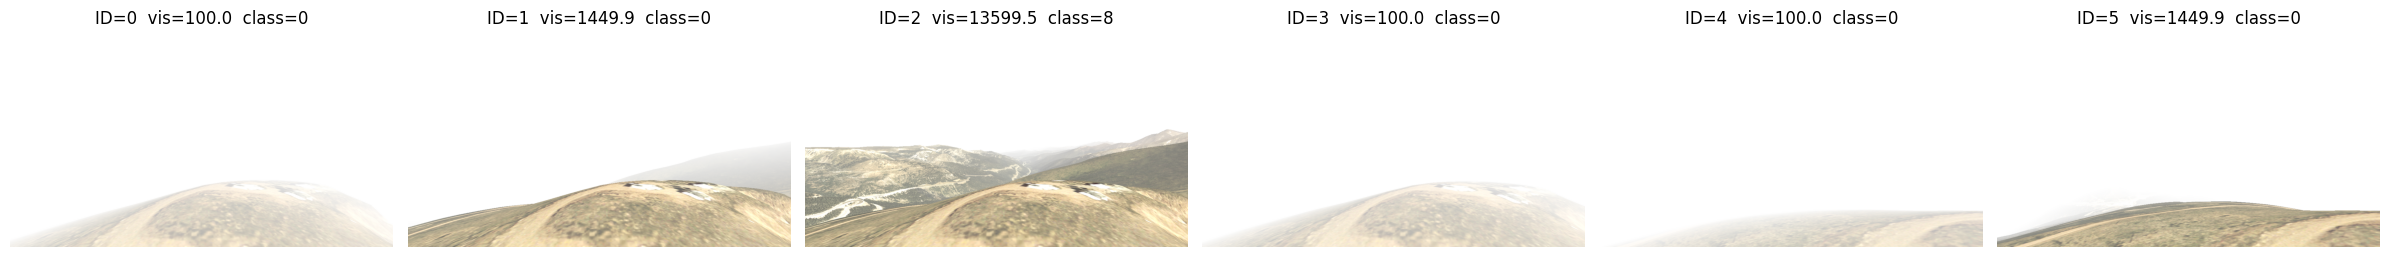

In [38]:
num_display = min(6, len(dataset))

fig, axes = plt.subplots(1, num_display, figsize=(4 * num_display, 4))
if num_display == 1:
    axes = [axes]

for i, ax in enumerate(axes):
    img, vis = dataset[i]
    # Convert CHW tensor to HWC numpy for matplotlib
    img_np = img.permute(1, 2, 0).numpy()  # HWC
    axes[i].imshow(img_np)
    axes[i].set_title(f"ID={i}  vis={dataset.raw_visibilities[i]:.1f}  class={vis.item()}")
    axes[i].axis("off")

plt.tight_layout()
plt.show()

## 4. Create a DataLoader

The `DataLoader` is what you pass to your PyTorch `Trainer` (or manual
training loop).  We also show how to add a torchvision transform.

In [39]:
# ---------- With a torchvision transform ----------
from torchvision.transforms.v2 import (  # newer API — falls back to functional\
    ToImage,
    ToDtype,
    Resize,
    Normalize,
    ToTensor
)

transform = tvf.Compose([
    Resize((224,224)),
    ToImage(),
    ToDtype(torch.float32, scale=True),  # [0, 255] -> [0, 1]
])

In [40]:
train_loader = get_dataloader(
    db_path=DB_PATH,
    image_root=IMAGE_DIR,
    batch_size=4,
    shuffle=True,
    transform=transform,
    label_transform=get_vis_distance_to_miles_transform,
    num_workers=0,
)

print(f"DataLoader batch size: {train_loader.batch_size}")
print(f"DataLoader length    : {len(train_loader)} batches")

# Iterate one batch
images, labels = next(iter(train_loader))
print(f"Batch images shape : {images.shape}")  # [B, C, H, W]
print(f"Batch labels       : {labels.tolist()}")
print(f"Batch label range  : [{labels.min():.2f}, {labels.max():.2f}]")

DataLoader batch size: 4
DataLoader length    : 8775 batches
Batch images shape : torch.Size([4, 3, 224, 224])
Batch labels       : [5, 4, 1, 5]
Batch label range  : [1.00, 5.00]


## 5. Distribution of Labels

A histogram of visibility distances helps guide loss weighting and scaling.

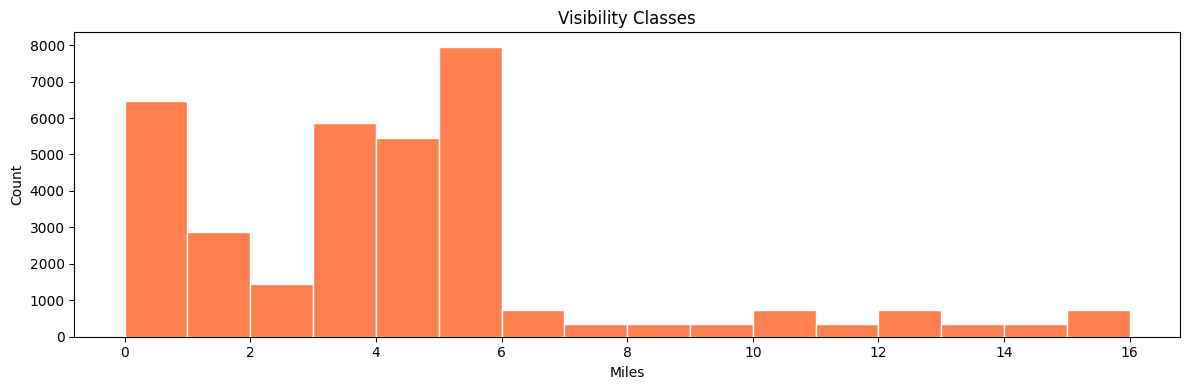

In [42]:
classes = dataset.labels.tolist()
bin_edges = np.arange(int(min(classes)), int(max(classes)) + 2)

fig, ax1 = plt.subplots(1, 1, figsize=(12, 4))
ax1.hist(classes, bins=bin_edges, color="coral", edgecolor="white")
ax1.set_title("Visibility Classes")
ax1.set_xlabel("Miles")
ax1.set_ylabel("Count")

plt.tight_layout()
plt.show()

## 6. Quick Training Sketch

Below is a minimal training loop showing how your DataLoader integrates into a
standard PyTorch training pipeline.

In [ ]:
import torch.nn as nn

# ——— Dummy model for demonstration ———
class FogVisibilityNet(nn.Module):
    """A minimal convolutional regressor (demo only)."""
    def __init__(self):
        super().__init__()
        self.backbone = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1),
            nn.ReLU(),
            nn.AdaptiveAvgPool2d(1),
            nn.Flatten(),
            nn.Linear(32, 1),
        )

    def forward(self, x):
        return self.backbone(x).squeeze(-1)  # [B]


model = FogVisibilityNet()
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

# ——— One epoch (demo) ———
model.train()
for batch_idx, (images, labels) in enumerate(train_loader):
    pred = model(images)
    loss = criterion(pred, labels)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    if batch_idx == 0:  # only print first batch
        print(f"Demo batch loss: {loss.item():.4f}")

print("Training loop completed successfully ✓")